In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [15]:
data_path="/Users/mo7ammedsharaki/programming/DATA QUEST/2026 ASA DataQuest/WPP2024_Demographic_Indicators_Medium_csv.gz"
data=pd.read_csv(data_path,compression="gzip",
                 encoding="utf-8-sig",
                 low_memory=False)
# df=pd.DataFrame(data)
data.columns

# data["TPopulation1Jan"]


Index(['SortOrder', 'LocID', 'Notes', 'ISO3_code', 'ISO2_code', 'SDMX_code',
       'LocTypeID', 'LocTypeName', 'ParentID', 'Location', 'VarID', 'Variant',
       'Time', 'TPopulation1Jan', 'TPopulation1July', 'TPopulationMale1July',
       'TPopulationFemale1July', 'PopDensity', 'PopSexRatio', 'MedianAgePop',
       'NatChange', 'NatChangeRT', 'PopChange', 'PopGrowthRate',
       'DoublingTime', 'Births', 'Births1519', 'CBR', 'TFR', 'NRR', 'MAC',
       'SRB', 'Deaths', 'DeathsMale', 'DeathsFemale', 'CDR', 'LEx', 'LExMale',
       'LExFemale', 'LE15', 'LE15Male', 'LE15Female', 'LE65', 'LE65Male',
       'LE65Female', 'LE80', 'LE80Male', 'LE80Female', 'InfantDeaths', 'IMR',
       'LBsurvivingAge1', 'Under5Deaths', 'Q5', 'Q0040', 'Q0040Male',
       'Q0040Female', 'Q0060', 'Q0060Male', 'Q0060Female', 'Q1550',
       'Q1550Male', 'Q1550Female', 'Q1560', 'Q1560Male', 'Q1560Female',
       'NetMigrations', 'CNMR'],
      dtype='object')

In [16]:
data_path="/Users/mo7ammedsharaki/programming/DATA QUEST/2026 ASA DataQuest/WPP2024_Demographic_Indicators_OtherVariants_csv.gz"
data=pd.read_csv(data_path,compression="gzip",
                 encoding="utf-8-sig",
                 low_memory=False)
# df=pd.DataFrame(data)
data.columns

# data["TPopulation1Jan"]


Index(['SortOrder', 'LocID', 'Notes', 'ISO3_code', 'ISO2_code', 'SDMX_code',
       'LocTypeID', 'LocTypeName', 'ParentID', 'Location', 'VarID', 'Variant',
       'Time', 'TPopulation1Jan', 'TPopulation1July', 'TPopulationMale1July',
       'TPopulationFemale1July', 'PopDensity', 'PopSexRatio', 'MedianAgePop',
       'NatChange', 'NatChangeRT', 'PopChange', 'PopGrowthRate',
       'DoublingTime', 'Births', 'Births1519', 'CBR', 'TFR', 'NRR', 'MAC',
       'SRB', 'Deaths', 'DeathsMale', 'DeathsFemale', 'CDR', 'LEx', 'LExMale',
       'LExFemale', 'LE15', 'LE15Male', 'LE15Female', 'LE65', 'LE65Male',
       'LE65Female', 'LE80', 'LE80Male', 'LE80Female', 'InfantDeaths', 'IMR',
       'LBsurvivingAge1', 'Under5Deaths', 'Q5', 'Q0040', 'Q0040Male',
       'Q0040Female', 'Q0060', 'Q0060Male', 'Q0060Female', 'Q1550',
       'Q1550Male', 'Q1550Female', 'Q1560', 'Q1560Male', 'Q1560Female',
       'NetMigrations', 'CNMR'],
      dtype='object')

Variant
High                                  43290
Momentum                              43290
Accelerated ABR decline with rec      43290
Accelerated ABR decline               43290
Low                                   43290
Instant replacement zero migration    43290
No fertility below age 18             43290
No change                             43290
Constant mortality                    43290
Zero migration                        43290
Instant replacement                   43290
Constant fertility                    43290
Median PI                             25038
Upper 80 PI                           25038
Lower 80 PI                           25038
Upper 95 PI                           25038
Lower 95 PI                           25038
Mean                                  18249
Name: count, dtype: int64


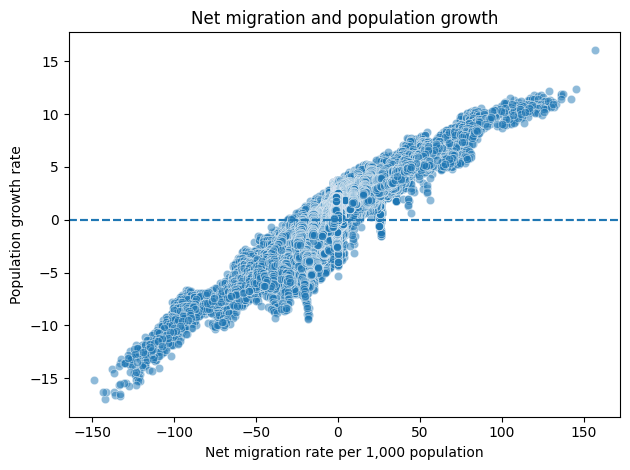

/Users/mo7ammedsharaki/programming/DATA QUEST/DATA_Env/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/mo7ammedsharaki/programming/DATA QUEST/DATA_Env/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/mo7ammedsharaki/programming/DATA QUEST/DATA_Env/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)


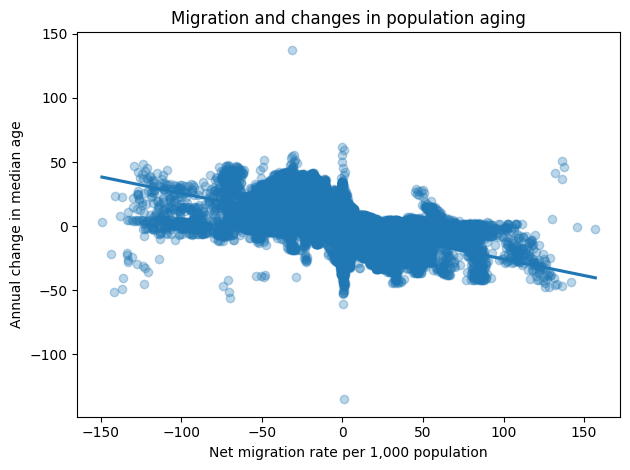

                 CNMR  PopGrowthRate  MedianAgePop  ChangeMedianAge   TFR  \
CNMR             1.00           0.79         -0.11            -0.38  0.24   
PopGrowthRate    0.79           1.00         -0.65            -0.49  0.67   
MedianAgePop    -0.11          -0.65          1.00             0.38 -0.77   
ChangeMedianAge -0.38          -0.49          0.38             1.00 -0.40   
TFR              0.24           0.67         -0.77            -0.40  1.00   
NatChangeRT      0.15           0.71         -0.92            -0.32  0.86   

                 NatChangeRT  
CNMR                    0.15  
PopGrowthRate           0.71  
MedianAgePop           -0.92  
ChangeMedianAge        -0.32  
TFR                     0.86  
NatChangeRT             1.00  


In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# Now call axhline on plt, not matplotlib_inline

# Keep one consistent scenario for the analysis.
print(data["Variant"].value_counts(dropna=False))

# Use the baseline/medium variant only if that is
# the appropriate label in your dataset.
# Check the actual labels before filtering.
data = data.copy()

# Convert key columns to numeric.
cols = [
    "Time", "CNMR", "NetMigrations", "MedianAgePop",
    "PopGrowthRate", "NatChangeRT", "TFR"
]

for col in cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Retain one observation per location and year.
data = data.dropna(
    subset=["ISO3_code", "Time", "MedianAgePop", "CNMR"]
)

data = data.sort_values(["ISO3_code", "Time"])

# Calculate annual changes in median age.
data["ChangeMedianAge"] = (
    data.groupby("ISO3_code")["MedianAgePop"].diff()
)

# Explore migration and population growth.
sns.scatterplot(
    data=data,
    x="CNMR",
    y="PopGrowthRate",
    alpha=0.5
)

plt.axhline(0, linestyle="--")
plt.axhline(0, linestyle="--")
plt.xlabel("Net migration rate per 1,000 population")
plt.ylabel("Population growth rate")
plt.title("Net migration and population growth")
plt.tight_layout()
plt.show()

# Explore migration and annual changes in median age.
sns.regplot(
    data=data,
    x="CNMR",
    y="ChangeMedianAge",
    scatter_kws={"alpha": 0.3}
)

plt.xlabel("Net migration rate per 1,000 population")
plt.ylabel("Annual change in median age")
plt.title("Migration and changes in population aging")
plt.tight_layout()
plt.show()

# Check the correlations among the key variables.
print(
    data[[
        "CNMR", "PopGrowthRate", "MedianAgePop",
        "ChangeMedianAge", "TFR", "NatChangeRT"
    ]].corr().round(2)
)
